# Pharmacy supply and geographic isolation in Vienna


**Research question:** How are pharmacies geographically distributed across Vienna, which districts have more isolated pharmacies, and does population density help explain these patterns? We will investigate district-level supply, and identify clusters with help of models such as K-means and DBSCAN. 

# EDA

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from pyproj import Transformer
from sklearn.cluster import KMeans
from sklearn.model_selection import KFold
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

sns.set_theme(style="whitegrid")
df = pd.read_csv("APOTHEKEOGD.csv")

In [2]:
df.head()

,FID,OBJECTID,SHAPE,BEZEICHNUNG,BEZIRK,STRASSE,ONR,ADRESSE,TELEFON,FAX,EMAIL,WEBLINK1,SE_ANNO_CAD_DATA
0,APOTHEKEOGD.2683636,2683636,POINT (16.420936840666634 48.23474672588274),Apotheke IZD-Tower,22,Wagramer Straße,19,"22., Wagramer Straße 19",01 263 20 30,01 263 20 30/4,kontakt@apotheke-izd-tower.at,NaN,NaN
1,APOTHEKEOGD.2683637,2683637,POINT (16.46403920483641 48.21989749706857),Apo22 beim Donauspital,22,Zschokkegasse,140,"22., Zschokkegasse 140",01 280 10 03,01 280 10 03/30,office@apo22.at,NaN,NaN
2,APOTHEKEOGD.2683638,2683638,POINT (16.306580678334765 48.22019488792717),Sandleiten-Apotheke,16,Nietzscheplatz,4,"16., Nietzscheplatz 4",01 486 21 43,01 486 21 43,sandleiten-apo@aponet.at,http://www.aponet.at/sandleitenapo,NaN
3,APOTHEKEOGD.2683639,2683639,POINT (16.33558294004634 48.20399658823297),Die Apotheke in der Lugner City,15,Gablenzgasse,5-14,"15., Gablenzgasse 5-13, UG 9",01/786 34 27,01/786 34 27-30,apo@apolugnercity.at,NaN,NaN
4,APOTHEKEOGD.2683640,2683640,POINT (16.377195425388322 48.231634059722694),Animo Apotheke,2,Wallensteinstraße,61,"2., Wallensteinstraße 61",01 280 80 40,01/ 80 80 40 20,office@animo-apotheke.at,https://www.animo-apotheke.at,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 358 entries, 0 to 357
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   FID               358 non-null    str    
 1   OBJECTID          358 non-null    int64  
 2   SHAPE             358 non-null    str    
 3   BEZEICHNUNG       358 non-null    str    
 4   BEZIRK            358 non-null    int64  
 5   STRASSE           358 non-null    str    
 6   ONR               357 non-null    str    
 7   ADRESSE           358 non-null    str    
 8   TELEFON           358 non-null    str    
 9   FAX               354 non-null    str    
 10  EMAIL             348 non-null    str    
 11  WEBLINK1          107 non-null    str    
 12  SE_ANNO_CAD_DATA  0 non-null      float64
dtypes: float64(1), int64(2), str(10)
memory usage: 101.0 KB


One house number is missing. Its coordinates are present, so this pharmacy can be included in the spatial analysis.

In [4]:
# Remove columns not needed for the analysis and rename others

df = df.drop(columns = ["FID","OBJECTID","TELEFON","FAX","EMAIL","WEBLINK1","SE_ANNO_CAD_DATA"])
df = df.rename(columns={
    "SHAPE": "geometry",
    "BEZEICHNUNG": "pharmacy_name",
    "BEZIRK": "district",
    "STRASSE": "street",
    "ONR": "house_number",
    "ADRESSE": "address"
})


In [5]:
df[df["house_number"].isnull()]

,geometry,pharmacy_name,district,street,house_number,address
339,POINT (16.466086706018896 48.154813147464864),"Regenbogenapotheke ""Am Leberberg""",11,Etrichstraße / Mühlsangergasse,NaN,"11., Etrichstraße 34"


In [6]:
df.loc[339, "house_number"] = "34" # correct missing house_number

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 358 entries, 0 to 357
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   geometry       358 non-null    str  
 1   pharmacy_name  358 non-null    str  
 2   district       358 non-null    int64
 3   street         358 non-null    str  
 4   house_number   358 non-null    str  
 5   address        358 non-null    str  
dtypes: int64(1), str(5)
memory usage: 54.9 KB


In [8]:
print("Remaining missing house numbers:", df["house_number"].isna().sum())

Remaining missing house numbers: 0


In [9]:
# Transform geometry to longitude / latitude 
pharmacies = df.copy()

coords = pharmacies["geometry"].str.extract(
    r"POINT\s*\(([-\d.]+)\s+([-\d.]+)\)"
)

pharmacies["longitude"] = pd.to_numeric(coords[0])
pharmacies["latitude"] = pd.to_numeric(coords[1])

pharmacies["district"] = pd.to_numeric(
    pharmacies["district"], errors="coerce"
)

pharmacies.head()


,geometry,pharmacy_name,district,street,house_number,address,longitude,latitude
0,POINT (16.420936840666634 48.23474672588274),Apotheke IZD-Tower,22,Wagramer Straße,19,"22., Wagramer Straße 19",16.420937,48.234747
1,POINT (16.46403920483641 48.21989749706857),Apo22 beim Donauspital,22,Zschokkegasse,140,"22., Zschokkegasse 140",16.464039,48.219897
2,POINT (16.306580678334765 48.22019488792717),Sandleiten-Apotheke,16,Nietzscheplatz,4,"16., Nietzscheplatz 4",16.306581,48.220195
3,POINT (16.33558294004634 48.20399658823297),Die Apotheke in der Lugner City,15,Gablenzgasse,5-14,"15., Gablenzgasse 5-13, UG 9",16.335583,48.203997
4,POINT (16.377195425388322 48.231634059722694),Animo Apotheke,2,Wallensteinstraße,61,"2., Wallensteinstraße 61",16.377195,48.231634


In [10]:
print(f"\nDuplicate rows: {pharmacies.duplicated().sum()}")


Duplicate rows: 0


In [11]:
# Map district to their number 

district_map = {
    1: "Innere Stadt",
    2: "Leopoldstadt",
    3: "Landstraße",
    4: "Wieden",
    5: "Margareten",
    6: "Mariahilf",
    7: "Neubau",
    8: "Josefstadt",
    9: "Alsergrund",
    10: "Favoriten",
    11: "Simmering",
    12: "Meidling",
    13: "Hietzing",
    14: "Penzing",
    15: "Rudolfsheim-Fünfhaus",
    16: "Ottakring",
    17: "Hernals",
    18: "Währing",
    19: "Döbling",
    20: "Brigittenau",
    21: "Floridsdorf",
    22: "Donaustadt",
    23: "Liesing"
}

pharmacies["District"] = pharmacies["district"].map(district_map)

## How does pharmacy supply vary by district?

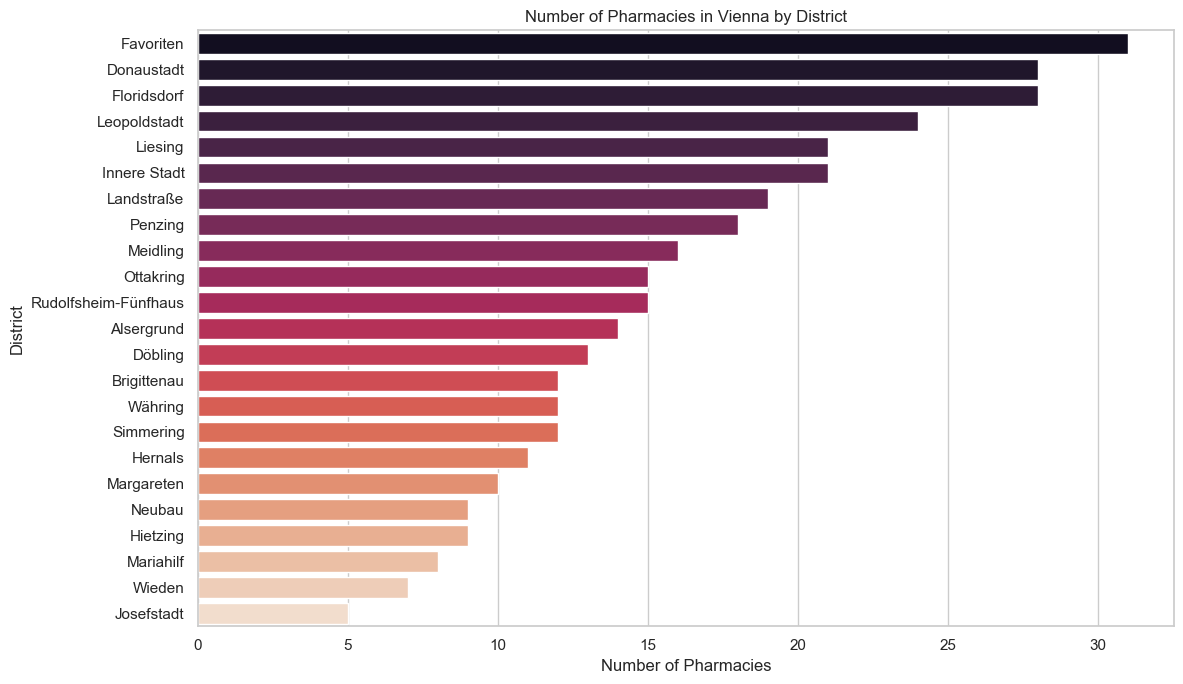

In [12]:
pharmacy_counts = (
    pharmacies["District"]
    .value_counts()
    .reset_index()
)

pharmacy_counts.columns = ["District", "nbr_pharmacies"]

plt.figure(figsize=(12, 7))

sns.barplot(
    data=pharmacy_counts,
    x="nbr_pharmacies",
    y="District",
    hue="District",
    palette="rocket",
    legend=False,
    orient="h"
)

plt.title("Number of Pharmacies in Vienna by District")
plt.xlabel("Number of Pharmacies")
plt.ylabel("District")
plt.tight_layout()
plt.show()

In [13]:
# Population CSV 
pop = pd.read_csv("vienna_population_clean.csv")

analysis = pop.merge(
    pharmacy_counts,
    on="District",
    how="left"
)

print(analysis.head())

       District  population  density  nbr_pharmacies
0    Donaustadt      228158     2230              28
1     Favoriten      223190     7013              31
2   Floridsdorf      189551     4265              28
3       Liesing      123714     3859              21
4  Leopoldstadt      112675     5856              24


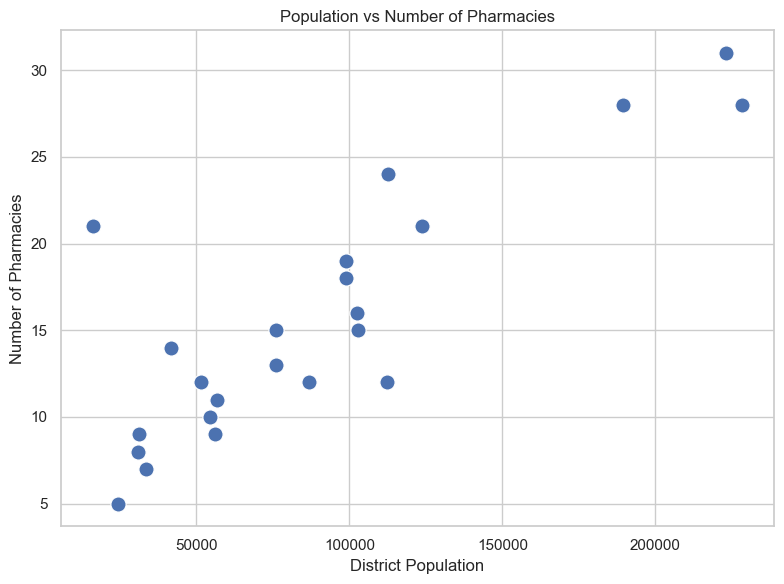

In [14]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=analysis,
    x="population",
    y="nbr_pharmacies",
    s=120
)

plt.title("Population vs Number of Pharmacies")
plt.xlabel("District Population")
plt.ylabel("Number of Pharmacies")
plt.tight_layout()
plt.show()

In [15]:
# correlation between of nrb_pharmacies and district population 
print(
    analysis[["population", "nbr_pharmacies"]]
    .corr()
)

                population  nbr_pharmacies
population        1.000000        0.839874
nbr_pharmacies    0.839874        1.000000


**Interpetation:** Favoriten has the most pharmacies (31). Larger populations generally go with larger pharmacy counts (Pearson r ≈ 0.84).

## Model Building 

### K-means

We begin by K-means to find clusters in our pharmacy data, we first need to transform coordinates to meters, we chose the optimal K by CV and Silhouette Score. 

In [16]:
# Convert coordinates to meters (UTM Zone 33N)
transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:32633", always_xy=True
)

valid = pharmacies[["longitude", "latitude"]].dropna()

x, y = transformer.transform(
    valid["longitude"].to_numpy(),
    valid["latitude"].to_numpy()
)

X = np.column_stack((x, y))

In [17]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

k_values = range(2, 11)
cv_scores = []

for k in k_values:
    scores = []

    for train_idx, test_idx in cv.split(X):
        X_train = X[train_idx]
        X_test = X[test_idx]

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        model.fit(X_train)
        labels = model.predict(X_test)
        if 2 <= len(np.unique(labels)) < len(X_test):
            score = silhouette_score(X_test, labels)
            scores.append(score)

    cv_scores.append(np.mean(scores) if scores else np.nan)

best_k = list(k_values)[np.nanargmax(cv_scores)]

print("Best K:", best_k)
print("Best CV Silhouette Score:", np.nanmax(cv_scores))


Best K: 2
Best CV Silhouette Score: 0.35390473359419833


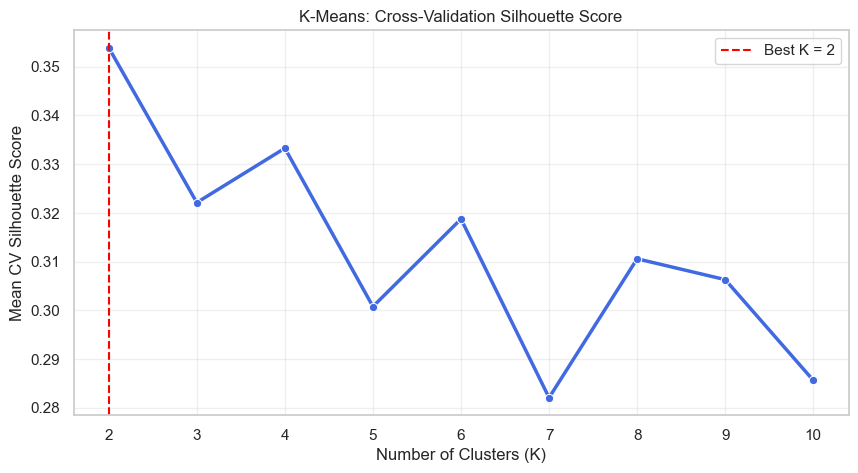

In [18]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=list(k_values),
    y=cv_scores,
    marker="o",
    color="royalblue",
    linewidth=2.5
)

plt.axvline(
    best_k,
    color="red",
    linestyle="--",
    label=f"Best K = {best_k}"
)

plt.title("K-Means: Cross-Validation Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Mean CV Silhouette Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

pharmacies.loc[valid.index, "cluster"] = kmeans.fit_predict(X)

print(pharmacies["cluster"].value_counts())

cluster
0.0    263
1.0     95
Name: count, dtype: int64


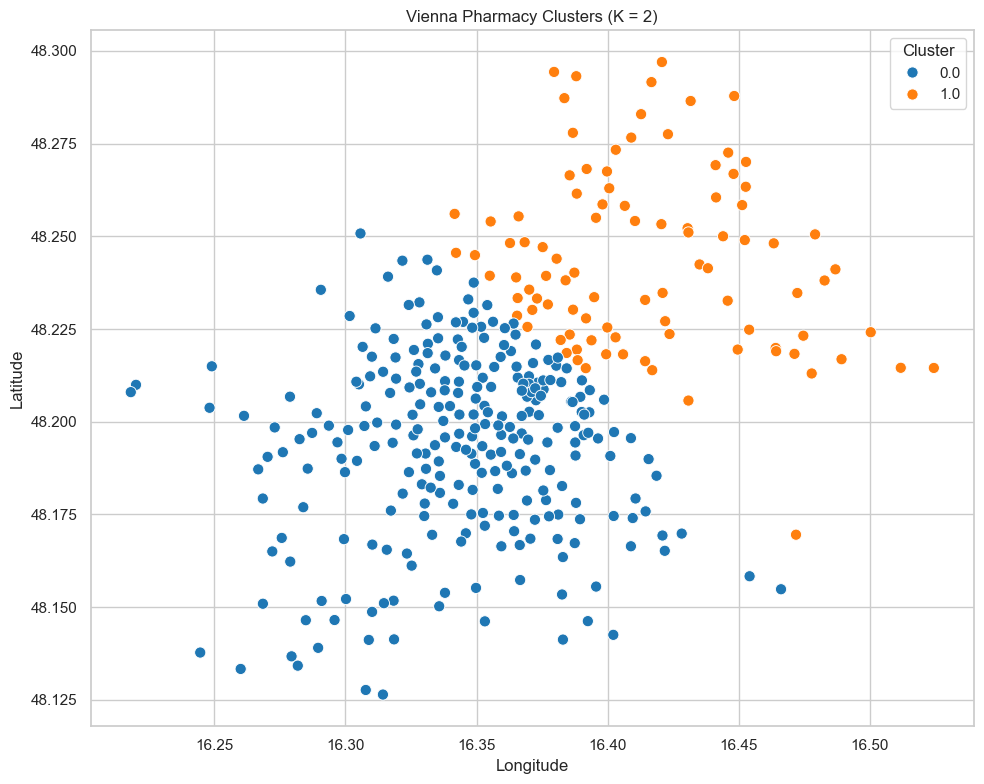

In [20]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=pharmacies,
    x="longitude",
    y="latitude",
    hue="cluster",
    palette="tab10",
    s=65
)

plt.title(f"Vienna Pharmacy Clusters (K = {best_k})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

**Interpetation:** Although K-Means identifies two geographical groups, it does not adequately capture the local spatial distribution of pharmacies. Therefore, we will try DBSCAN for further analysis. 

### DBSCAN

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is an unsupervised machine learning algorithm that groups data points based on their spatial density. It identifies clusters of closely located points while distinguishing isolated points as noise or outliers.

DBSCAN relies on two main parameters:
- **Epsilon (eps):** The maximum distance between neighboring points.
- **Minimum samples (min_samples):** The minimum number of points required within a neighborhood to form a dense region, including the point itself.
  
*the K-means classify depending on the distance to cluster mean only, ignoring how areas could be more dense than others.*


In [21]:
valid_geo = pharmacies[["latitude", "longitude"]].dropna()
X_geo = np.radians(valid_geo.to_numpy()) # Transform coords to radians 

earth_radius_km = 6371.0088
radius_km = 1.0
min_pts = 3 

dbscan = DBSCAN(
    eps=radius_km / earth_radius_km,
    min_samples=min_pts,
    metric="haversine"
)
labels = dbscan.fit_predict(X_geo)
pharmacies["dbscan_cluster"] = np.nan
pharmacies.loc[valid_geo.index, "dbscan_cluster"] = labels
n_clusters = len(set(labels) - {-1})
n_noise = int(np.sum(labels == -1))
print("Number of clusters:", n_clusters)
print("Noise pharmacies:", n_noise)
print("Noise percentage:", round(100 * n_noise / len(labels), 2))
print(pharmacies["dbscan_cluster"].value_counts())

Number of clusters: 11
Noise pharmacies: 33
Noise percentage: 9.22
dbscan_cluster
 2.0     260
-1.0      33
 4.0      19
 3.0      12
 1.0       8
 5.0       7
 0.0       4
 6.0       3
 9.0       3
 7.0       3
 8.0       3
 10.0      3
Name: count, dtype: int64


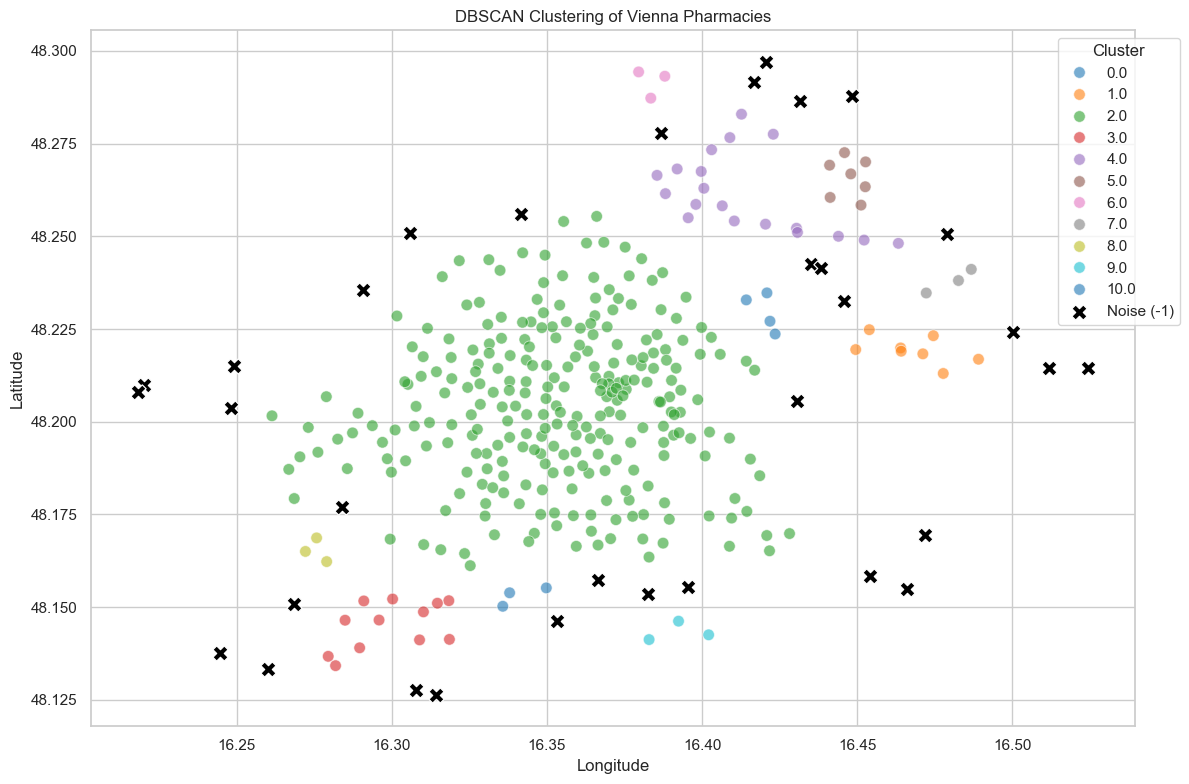

In [22]:
plt.figure(figsize=(12, 8))

# Plot normal clusters only

sns.scatterplot(
    data=pharmacies[pharmacies["dbscan_cluster"] != -1],
    x="longitude",
    y="latitude",
    hue="dbscan_cluster",
    palette="tab10",
    s=70,
    alpha=0.6
)

# Plot noise points (-1) 

sns.scatterplot(
    data=pharmacies[pharmacies["dbscan_cluster"] == -1],
    x="longitude",
    y="latitude",
    color="black",
    s=120,
    alpha=1,
    marker="X",
    label="Noise (-1)"
)

plt.title("DBSCAN Clustering of Vienna Pharmacies")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Where are pharmacies geographically isolated?
The noise of our model could represent isolated pharmacies. 

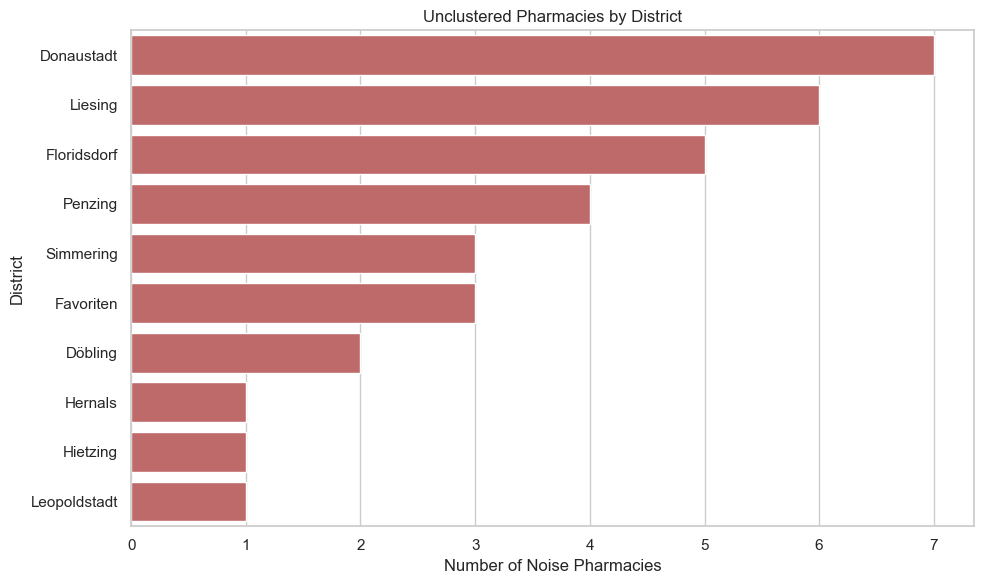

In [23]:
noise = pharmacies[
    pharmacies["dbscan_cluster"] == -1
]

noise_summary = (
    noise.groupby("District")
    .size()
    .reset_index(name="noise_count")
    .sort_values("noise_count", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=noise_summary,
    x="noise_count",
    y="District",
    color="indianred"
)

plt.title("Unclustered Pharmacies by District")
plt.xlabel("Number of Noise Pharmacies")
plt.ylabel("District")
plt.tight_layout()
plt.show()

**Interpetation:** At 1 km, 33 of 358 pharmacies (9.2%) are unclustered. The largest cluster contains 260 pharmacies across 20 districts. A cluster can extend beyond 1 km because neighbouring core locations connect to each other.

Donaustadt has the largest count of unclustered pharmacies (7 of 28, or 25%). Liesing has the largest share (6 of 21, or 28.6%).

Therefore is most populated area in Vienna has the most Isolated pharmacies there.

## Is the unclustered share depend on densely populated districts?

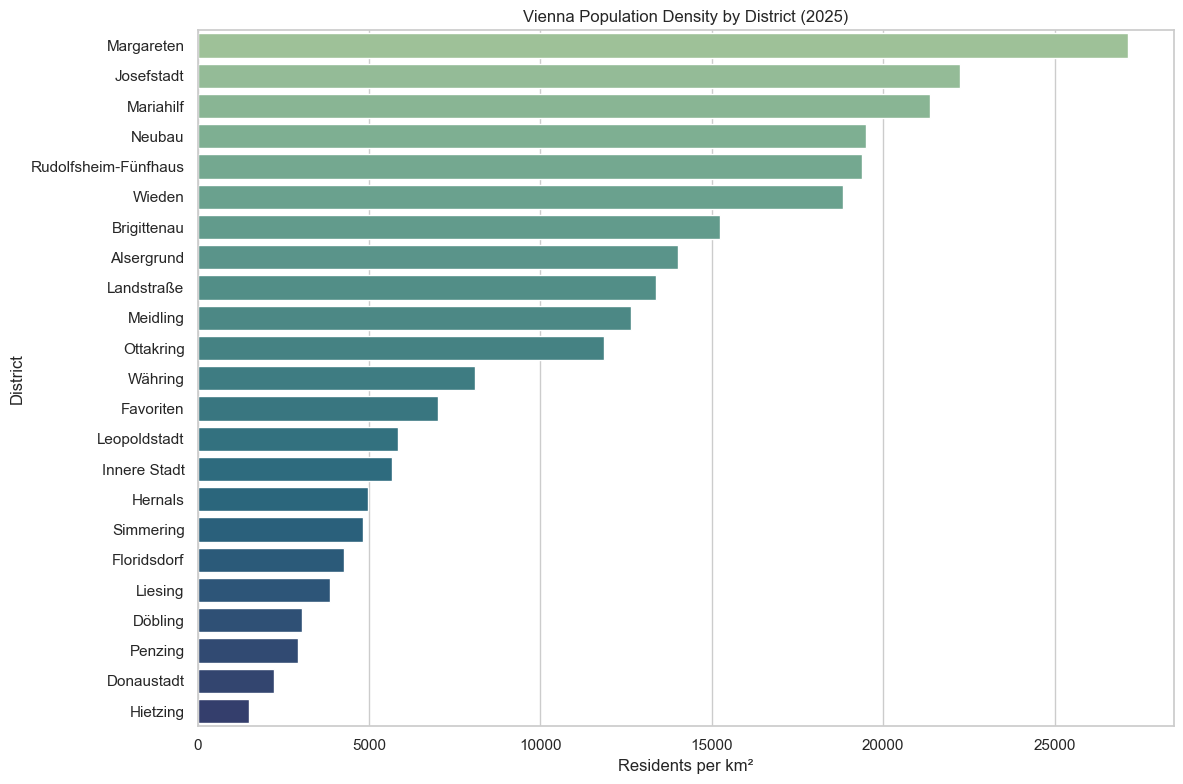

In [24]:
pop = pd.read_csv("vienna_population_clean.csv")
pop = pop.sort_values(by="density", ascending=False)


plt.figure(figsize=(12, 8))

sns.barplot(
    data=pop,
    x="density",
    y="District",
    hue="District",
    palette="crest",
    legend=False
)

plt.title("Vienna Population Density by District (2025)")
plt.xlabel("Residents per km²")
plt.ylabel("District")
plt.tight_layout()
plt.show()

**Interpetation:** The number of pharmacies depends on the population of each district, while the geographic isolation of pharmacies appears to depend strongly on the population density of the area being studied.

## Relation between number of isolated pharmacies and density in districts

In [25]:
analysis = pop.merge(noise_summary, on="District", how="left")
analysis = analysis.merge(pharmacy_counts, on="District", how="left")

# district with no noise 
analysis["noise_count"] = analysis["noise_count"].fillna(0)

analysis["noise_percentage"] = (
    analysis["noise_count"] / analysis["nbr_pharmacies"] * 100
)

analysis = analysis.sort_values(by="noise_percentage", ascending=False)
analysis.head()

,District,population,density,noise_count,nbr_pharmacies,noise_percentage
18,Liesing,123714,3859,6.0,21,28.571429
16,Simmering,112149,4822,3.0,12,25.000000
21,Donaustadt,228158,2230,7.0,28,25.000000
20,Penzing,99049,2934,4.0,18,22.222222
17,Floridsdorf,189551,4265,5.0,28,17.857143


In [26]:
from scipy.stats import spearmanr

corr, p_value = spearmanr(
    analysis["density"],
    analysis["noise_percentage"]
)

print(f"Spearman correlation: {corr:.3f}")
print(f"P-value: {p_value:.4f}")

Spearman correlation: -0.842
P-value: 0.0000


**Interpetation:** We have strong negative correlation (Spearman's ρ = −0.80) between population density and the percentage of isolated pharmacies classified as noise by DBSCAN. This indicates that pharmacies in less densely populated districts tend to be more geographically isolated

# 6. Summary

## 6.1 Pharmacy Distribution and Population

Our analysis investigates the geographic distribution of **358 pharmacies across Vienna's 23 districts**.

We found a **strong positive correlation (Pearson's r ≈ 0.84)** between district population and the number of pharmacies. This indicates that more populated districts generally have more pharmacies.

**Favoriten** has the highest number of pharmacies (31), while **Donaustadt** has the largest population (228,158 residents) and 28 pharmacies.

However, the total number of pharmacies does not necessarily reflect their geographic accessibility or distribution within each district.

## 6.2 K-Means Clustering

We applied K-Means clustering to identify broad geographic patterns in pharmacy locations.

The selected model produced **two clusters**, containing 263 and 95 pharmacies, with a mean cross-validation Silhouette Score of approximately **0.354**.

Although K-Means identifies broad geographic groups, it is less suitable for detecting isolated pharmacies because every pharmacy is assigned to a cluster.

## 6.3 DBSCAN and Geographic Isolation

To investigate pharmacy isolation, we applied DBSCAN using a **1 km neighborhood radius** and a minimum of three pharmacies.

The recorded results show:

- **11 geographic clusters**.
- **33 pharmacies classified as noise (9.22%)**.

Regarding geographic isolation, **Donaustadt** (7 pharmacies, 25%) and **Liesing** (6 pharmacies, 28.6%) stand out as districts worth investigating further.

These figures should be verified using the corrected DBSCAN analysis.

## 6.4 Population Density and Isolation

We investigated whether population density could help explain the geographic isolation of pharmacies.

Our hypothesis was that pharmacies tend to be more geographically separated in less densely populated districts.

To test this, we compared population density with the percentage of pharmacies classified as noise in each district using **Spearman's rank correlation test**.

We found a **strong negative correlation (Spearman's ρ ≈ −0.80)**, suggesting that pharmacies in less densely populated districts tend to be more geographically isolated.

**This supports our hypothesis that population density is strongly associated with pharmacy isolation**, although correlation does not establish causation.

## 6.5 Limitations

First, district-level population density does not show how residents are distributed within individual neighborhoods. Large districts may contain both densely populated and sparsely populated areas.

Second, geographic distances between pharmacies do not represent actual walking distances or travel times.

## 6.6 Future Work

Future work could address these limitations by analyzing neighborhood-level population distribution and walking distances to existing pharmacies.

This would help us **identify underserved areas and investigate optimal locations for new pharmacies**, moving beyond geographic clustering toward a more complete accessibility analysis.